In [1]:
# Install/import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from google.colab import files
from IPython.display import display

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
project_info = {
    "Project": "Mini AI Cybersecurity Assistant",
    "Course": "ENSP355 - AI in Cyber Security",
    "Platform": "Google Colab",
    "Rule-Based AI": "Keyword matching",
    "Machine Learning": "Decision Tree",
    "Deep Learning": "Dense Neural Network",
    "Privacy": "Identifier masking",
    "Response": "Risk assessment and human review"
}

for key, value in project_info.items():
    print(f"{key}: {value}")

print("\nPROJECT ARCHITECTURE")
print("""
1. Input and Privacy Module
2. Rule-Based Threat Detector
3. Decision Tree Classifier
4. Neural Network Classifier
5. Explanation Module
6. Risk and Response Module
7. Human Review Module
""")

Project: Mini AI Cybersecurity Assistant
Course: ENSP355 - AI in Cyber Security
Platform: Google Colab
Rule-Based AI: Keyword matching
Machine Learning: Decision Tree
Deep Learning: Dense Neural Network
Privacy: Identifier masking
Response: Risk assessment and human review

PROJECT ARCHITECTURE

1. Input and Privacy Module
2. Rule-Based Threat Detector
3. Decision Tree Classifier
4. Neural Network Classifier
5. Explanation Module
6. Risk and Response Module
7. Human Review Module



In [5]:
print("Please upload TWO CSV files:")
print("1. Message / phishing dataset")
print("2. Login activity dataset")

uploaded_files = files.upload()

csv_files = list(uploaded_files.keys())

if len(csv_files) < 2:
    raise ValueError(
        "Please upload both required CSV files and run this cell again."
    )

print("\nUploaded files:")
for f in csv_files:
    print("-", f)

Please upload TWO CSV files:
1. Message / phishing dataset
2. Login activity dataset


Saving simple_login_activity.csv to simple_login_activity (1).csv
Saving simple_cyber_activity.csv to simple_cyber_activity.csv

Uploaded files:
- simple_login_activity (1).csv
- simple_cyber_activity.csv


In [6]:
# Mask email addresses
def mask_email(text):

    text = str(text)

    return re.sub(
        r'[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}',
        '[MASKED_EMAIL]',
        text
    )


# Mask IPv4 addresses
def mask_ip(text):

    text = str(text)

    return re.sub(
        r'\b(?:\d{1,3}\.){3}\d{1,3}\b',
        '[MASKED_IP]',
        text
    )


# Mask account identifiers
def mask_account(text):

    text = str(text)

    return re.sub(
        r'\bACC[-_]?\w+\b',
        '[MASKED_ACCOUNT]',
        text,
        flags=re.IGNORECASE
    )


# Combined text masking
def mask_text(text):

    text = mask_email(text)
    text = mask_ip(text)
    text = mask_account(text)

    return text


print("PRIVACY MASKING EXAMPLES")

example = (
    "Contact admin@example.com from 192.168.1.25 "
    "using account ACC-1001"
)

print("Original:", example)
print("Masked:", mask_text(example))

PRIVACY MASKING EXAMPLES
Original: Contact admin@example.com from 192.168.1.25 using account ACC-1001
Masked: Contact [MASKED_EMAIL] from [MASKED_IP] using [MASKED_ACCOUNT] [MASKED_ACCOUNT]


In [7]:
threat_keywords = {

    'Phishing': [
        'verify account',
        'urgent',
        'password',
        'click here',
        'login now',
        'bank details',
        'account suspended',
        'confirm your identity',
        'otp'
    ],

    'Malware': [
        'malware',
        'virus',
        'trojan',
        'infected file',
        'malicious attachment',
        'download executable',
        'spyware'
    ],

    'Ransomware': [
        'ransomware',
        'encrypted files',
        'pay ransom',
        'bitcoin payment',
        'decrypt files',
        'files locked'
    ]
}

print("THREAT KEYWORD DICTIONARY")

for category, keywords in threat_keywords.items():

    print("\n", category)

    for word in keywords:
        print("-", word)

THREAT KEYWORD DICTIONARY

 Phishing
- verify account
- urgent
- password
- click here
- login now
- bank details
- account suspended
- confirm your identity
- otp

 Malware
- malware
- virus
- trojan
- infected file
- malicious attachment
- download executable
- spyware

 Ransomware
- ransomware
- encrypted files
- pay ransom
- bitcoin payment
- decrypt files
- files locked


In [8]:
def rule_detector(message):

    clean_message = mask_text(message).lower()

    matched_keywords = []
    matched_categories = []

    for category, keywords in threat_keywords.items():

        matches = [
            word for word in keywords
            if word in clean_message
        ]

        if matches:
            matched_categories.append(category)
            matched_keywords.extend(matches)

    if matched_categories:

        category = ", ".join(matched_categories)

    else:

        category = "Safe"

    keyword_score = len(matched_keywords)

    return category, matched_keywords, keyword_score


# Test the rule detector
test_messages = [

    "Hello, your meeting is scheduled for tomorrow.",

    "Urgent! Verify account and click here to confirm your password.",

    "Download this infected file containing a trojan.",

    "Your files are encrypted. Pay ransom using bitcoin.",

    "Your account has an unusual login attempt."
]

for message in test_messages:

    category, matched, score = rule_detector(message)

    print("\nMessage:", mask_text(message))
    print("Category:", category)
    print("Matched Keywords:", matched)
    print("Keyword Score:", score)


Message: Hello, your meeting is scheduled for tomorrow.
Category: Safe
Matched Keywords: []
Keyword Score: 0

Message: Urgent! Verify [MASKED_ACCOUNT] and click here to confirm your password.
Category: Phishing
Matched Keywords: ['urgent', 'password', 'click here']
Keyword Score: 3

Message: Download this infected file containing a trojan.
Category: Malware
Matched Keywords: ['trojan', 'infected file']
Keyword Score: 2

Message: Your files are encrypted. Pay ransom using bitcoin.
Category: Ransomware
Matched Keywords: ['pay ransom']
Keyword Score: 1

Message: Your [MASKED_ACCOUNT] has an unusual login attempt.
Category: Safe
Matched Keywords: []
Keyword Score: 0


In [14]:
import pandas as pd
import numpy as np
from google.colab import files

# Upload both CSV files again
print("Upload your TWO CSV files")

uploaded_files = files.upload()

csv_files = list(uploaded_files.keys())

if len(csv_files) < 2:
    raise ValueError("Please upload both CSV files.")

# Load datasets
dataframes = {}

for filename in csv_files:
    dataframes[filename] = pd.read_csv(filename)

# Normalize column names
for filename in dataframes:
    dataframes[filename].columns = (
        dataframes[filename].columns
        .str.strip()
        .str.lower()
    )

# Identify login dataset
login_file = None

for filename, data in dataframes.items():

    cols = data.columns.tolist()

    if (
        'failed_logins' in cols
        and 'login_hour' in cols
        and 'new_device' in cols
        and (
            'download_mb' in cols
            or 'data_transfer_mb' in cols
        )
    ):
        login_file = filename
        break

if login_file is None:
    print("Available CSV columns:")

    for filename, data in dataframes.items():
        print(filename, data.columns.tolist())

    raise ValueError("Login dataset could not be identified.")

# Assign login dataset
login_df = dataframes[login_file].copy()

# Rename feature if necessary
if 'data_transfer_mb' in login_df.columns:
    login_df.rename(
        columns={'data_transfer_mb': 'download_mb'},
        inplace=True
    )

# Identify target
target_candidates = [
    'label',
    'target',
    'class',
    'activity'
]

target_col = next(
    (col for col in target_candidates if col in login_df.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Target column missing. Check the displayed CSV columns."
    )

# Prepare features
features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'download_mb'
]

for col in features:
    login_df[col] = pd.to_numeric(
        login_df[col],
        errors='coerce'
    )

# Prepare target
y = login_df[target_col].copy()

if not pd.api.types.is_numeric_dtype(y):

    label_map = {
        'normal': 0,
        'safe': 0,
        'suspicious': 1,
        'attack': 1
    }

    y = y.astype(str).str.strip().str.lower().map(label_map)

X = login_df[features].copy()

# Remove missing values
valid = X.notna().all(axis=1) & y.notna()

X = X.loc[valid]
y = y.loc[valid].astype(int)

# Store cleaned dataset
login_df = login_df.loc[valid].copy()

print("\nSUCCESS! DATASET LOADED")
print("Login dataset:", login_file)
print("Target column:", target_col)
print("Features:", features)
print("Dataset shape:", X.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nDataset preview:")
display(login_df.head())

Upload your TWO CSV files


Saving simple_login_activity.csv to simple_login_activity (2).csv
Saving simple_cyber_activity.csv to simple_cyber_activity (1).csv

SUCCESS! DATASET LOADED
Login dataset: simple_login_activity (2).csv
Target column: label
Features: ['failed_logins', 'login_hour', 'new_device', 'download_mb']
Dataset shape: (99, 4)

Class distribution:
label
0    74
1    25
Name: count, dtype: int64

Dataset preview:


,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal


In [16]:
# IMPORT REQUIRED LIBRARIES

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# STEP 1: Verify dataset variables

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

# STEP 2: Split dataset

class_counts = y.value_counts()

if len(class_counts) < 2:
    raise ValueError("Dataset must contain Normal and Suspicious classes.")

stratify_value = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=stratify_value
)

print("\nDATASET SPLIT SUCCESSFUL!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# STEP 3: Create Decision Tree

tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# STEP 4: Train model

tree.fit(X_train, y_train)

# STEP 5: Make predictions

tree_predictions = tree.predict(X_test)

# STEP 6: Calculate accuracy

tree_accuracy = accuracy_score(
    y_test,
    tree_predictions
)

print("\nDECISION TREE TRAINED SUCCESSFULLY!")

print("Accuracy:",
      round(tree_accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    tree_predictions,
    zero_division=0
))

print("\nCONFUSION MATRIX")

print(confusion_matrix(
    y_test,
    tree_predictions
))

Dataset shape: (99, 4)
Target shape: (99,)

DATASET SPLIT SUCCESSFUL!
Training records: 74
Testing records: 25

DECISION TREE TRAINED SUCCESSFULLY!
Accuracy: 92.0 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        19
           1       0.83      0.83      0.83         6

    accuracy                           0.92        25
   macro avg       0.89      0.89      0.89        25
weighted avg       0.92      0.92      0.92        25


CONFUSION MATRIX
[[18  1]
 [ 1  5]]


FEATURE IMPORTANCE


,Feature,Importance
0,failed_logins,0.391554
3,download_mb,0.281985
1,login_hour,0.249961
2,new_device,0.076500


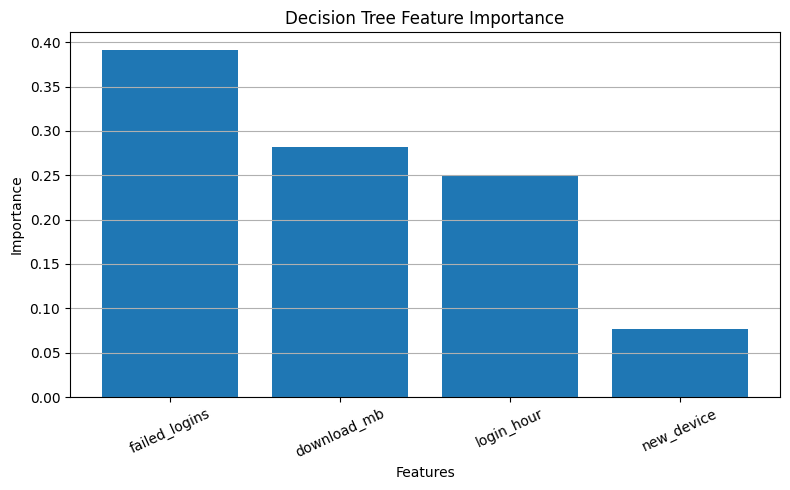

In [17]:
importance = pd.DataFrame({

    'Feature': features,

    'Importance': tree.feature_importances_

}).sort_values(
    by='Importance',
    ascending=False
)

print("FEATURE IMPORTANCE")
display(importance)

plt.figure(figsize=(8, 5))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=25)
plt.grid(axis='y')
plt.tight_layout()

plt.show()

In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nNormalization completed successfully!")

Training data shape: (74, 4)
Testing data shape: (25, 4)

Normalization completed successfully!


In [19]:
# Build 4-8-4-1 neural network

nn = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(4,)),

    tf.keras.layers.Dense(
        8,
        activation='relu'
    ),

    tf.keras.layers.Dense(
        4,
        activation='relu'
    ),

    tf.keras.layers.Dense(
        1,
        activation='sigmoid'
    )

])

# Compile model
nn.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']

)

# Model summary
nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [20]:
history = nn.fit(

    X_train_scaled,

    y_train,

    epochs=20,

    batch_size=8,

    validation_split=0.20,

    verbose=1

)

print("\nNeural Network Training Completed!")

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.2712 - loss: 0.8080 - val_accuracy: 0.3333 - val_loss: 0.7133
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2881 - loss: 0.7889 - val_accuracy: 0.3333 - val_loss: 0.7069
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3051 - loss: 0.7722 - val_accuracy: 0.4000 - val_loss: 0.7013
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3390 - loss: 0.7579 - val_accuracy: 0.4667 - val_loss: 0.6962
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3898 - loss: 0.7454 - val_accuracy: 0.5333 - val_loss: 0.6924
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4576 - loss: 0.7349 - val_accuracy: 0.6000 - val_loss: 0.6888
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.4915 - loss: 0.7269 - val_accuracy: 0.6000 - val_loss: 0.6852
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5254 - loss: 0.7205 - val_accuracy: 0.6000 - val_loss: 0.6817

In [21]:
nn_loss, nn_accuracy = nn.evaluate(

    X_test_scaled,

    y_test,

    verbose=0

)

print("NEURAL NETWORK RESULTS")

print(
    "Test Accuracy:",
    round(nn_accuracy * 100, 2),
    "%"
)

print(
    "Test Loss:",
    round(nn_loss, 4)
)

NEURAL NETWORK RESULTS
Test Accuracy: 64.0 %
Test Loss: 0.6684


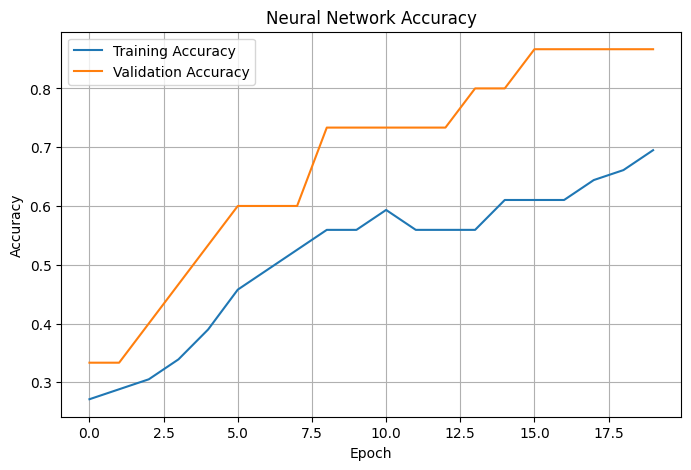

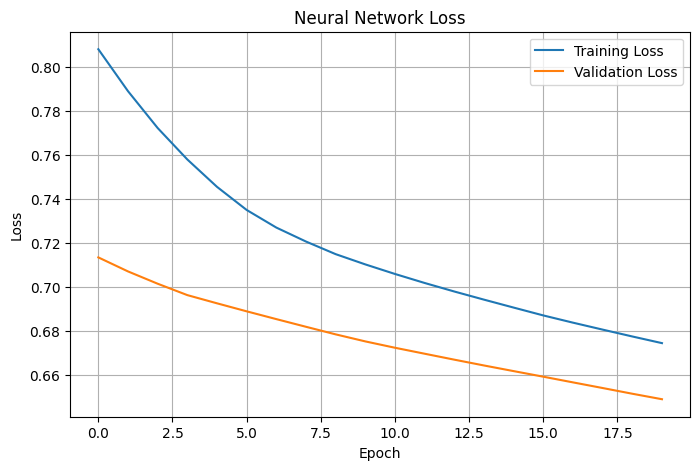

In [22]:
# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()


# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

In [23]:
def cybersecurity_assistant(
    message,
    failed_logins,
    login_hour,
    new_device,
    download_mb,
    ip_address,
    account_id
):

    # 1. Privacy masking
    clean_message = mask_text(message)

    masked_ip = mask_ip(ip_address)

    masked_account = mask_account(account_id)

    # 2. Rule-based message analysis
    rule_category, matched, keyword_score = rule_detector(
        clean_message
    )

    # 3. Create numeric input
    numeric = pd.DataFrame([{

        'failed_logins': failed_logins,

        'login_hour': login_hour,

        'new_device': new_device,

        'download_mb': download_mb

    }])

    # 4. Decision Tree prediction
    tree_value = int(tree.predict(numeric)[0])

    tree_confidence = float(
        tree.predict_proba(numeric).max()
    )

    tree_result = (
        'Suspicious'
        if tree_value == 1
        else 'Normal'
    )

    # 5. Neural Network prediction
    scaled_numeric = scaler.transform(numeric)

    nn_probability = float(
        nn.predict(
            scaled_numeric,
            verbose=0
        ).flatten()[0]
    )

    nn_result = (
        'Suspicious'
        if nn_probability >= 0.50
        else 'Normal'
    )

    nn_confidence = max(
        nn_probability,
        1 - nn_probability
    )

    # 6. Rule-based result
    rule_result = (
        'Suspicious'
        if rule_category != 'Safe'
        else 'Normal'
    )

    # 7. Warning votes
    warning_votes = (
        int(rule_result == 'Suspicious')
        + int(tree_result == 'Suspicious')
        + int(nn_result == 'Suspicious')
    )

    # 8. Check disagreement and confidence
    results = [
        rule_result,
        tree_result,
        nn_result
    ]

    conflict = len(set(results)) > 1

    low_confidence = (
        tree_confidence < 0.70
        or nn_confidence < 0.70
    )

    # 9. Numeric reasons
    reasons = []

    if failed_logins >= 5:
        reasons.append('Many failed login attempts')

    if new_device == 1:
        reasons.append('New device detected')

    if login_hour < 6 or login_hour > 22:
        reasons.append('Unusual login time')

    if download_mb >= 500:
        reasons.append('Large data download')

    if matched:
        reasons.append(
            'Threat keywords: ' + ', '.join(matched)
        )

    if not reasons:
        reasons.append('No strong warning indicators')

    # 10. Risk assignment
    if warning_votes >= 2:
        risk = 'High'

        action = (
            'Verify the activity, investigate the account '
            'and escalate to an authorized security analyst.'
        )

    elif warning_votes == 1 or conflict or low_confidence:
        risk = 'Medium'

        action = (
            'Review the message and login activity '
            'before taking further action.'
        )

    else:
        risk = 'Low'

        action = (
            'Continue normal monitoring and follow '
            'standard security practices.'
        )

    # 11. Human review
    human_review = (
        'Yes'
        if risk == 'High' or conflict or low_confidence
        else 'No'
    )

    # 12. Return integrated results
    return {

        'masked_account': masked_account,

        'masked_ip': masked_ip,

        'rule_category': rule_category,

        'matched_keywords': ', '.join(matched) if matched else 'None',

        'keyword_score': keyword_score,

        'tree_prediction': tree_result,

        'tree_confidence': round(tree_confidence, 3),

        'nn_prediction': nn_result,

        'nn_probability': round(nn_probability, 3),

        'warning_votes': warning_votes,

        'explanation': '; '.join(reasons),

        'risk': risk,

        'recommended_action': action,

        'human_review': human_review

    }


print("Integrated Cybersecurity Assistant created successfully!")

Integrated Cybersecurity Assistant created successfully!


In [24]:
# Test one example

result = cybersecurity_assistant(

    message="Urgent! Verify account and click here to confirm password.",

    failed_logins=7,

    login_hour=2,

    new_device=1,

    download_mb=250,

    ip_address="192.168.10.24",

    account_id="ACC-1001"

)

print("INTEGRATED CYBERSECURITY ASSISTANT RESULT")

for key, value in result.items():

    print(f"{key}: {value}")

INTEGRATED CYBERSECURITY ASSISTANT RESULT
masked_account: [MASKED_ACCOUNT]
masked_ip: [MASKED_IP]
rule_category: Phishing
matched_keywords: urgent, password, click here
keyword_score: 3
tree_prediction: Suspicious
tree_confidence: 1.0
nn_prediction: Suspicious
nn_probability: 0.511
warning_votes: 3
explanation: Many failed login attempts; New device detected; Unusual login time; Threat keywords: urgent, password, click here
risk: High
recommended_action: Verify the activity, investigate the account and escalate to an authorized security analyst.
human_review: Yes


In [25]:
scenarios = [

    {
        'scenario': 'Scenario 1 - Normal Activity',

        'message': 'Hello, your meeting is scheduled for tomorrow.',

        'failed_logins': 0,
        'login_hour': 10,
        'new_device': 0,
        'download_mb': 40
    },

    {
        'scenario': 'Scenario 2 - Phishing Message',

        'message': 'Urgent! Verify account and click here to confirm your password.',

        'failed_logins': 1,
        'login_hour': 11,
        'new_device': 0,
        'download_mb': 50
    },

    {
        'scenario': 'Scenario 3 - Suspicious Login',

        'message': 'Multiple login attempts detected on your account.',

        'failed_logins': 8,
        'login_hour': 2,
        'new_device': 1,
        'download_mb': 150
    },

    {
        'scenario': 'Scenario 4 - Large Download',

        'message': 'An unusually large file download was detected.',

        'failed_logins': 2,
        'login_hour': 23,
        'new_device': 1,
        'download_mb': 850
    },

    {
        'scenario': 'Scenario 5 - Conflicting Results',

        'message': 'Your account activity needs additional verification.',

        'failed_logins': 0,
        'login_hour': 10,
        'new_device': 0,
        'download_mb': 40
    }

]

scenario_results = []

for scenario in scenarios:

    result = cybersecurity_assistant(

        message=scenario['message'],

        failed_logins=scenario['failed_logins'],

        login_hour=scenario['login_hour'],

        new_device=scenario['new_device'],

        download_mb=scenario['download_mb'],

        ip_address="192.168.1.25",

        account_id="ACC-1001"

    )

    result['scenario'] = scenario['scenario']

    scenario_results.append(result)


# Create final scenario table
final_results = pd.DataFrame(scenario_results)

print("ALL FIVE SCENARIOS COMPLETED")

display(final_results[[
    'scenario',
    'rule_category',
    'tree_prediction',
    'nn_prediction',
    'risk',
    'recommended_action',
    'human_review'
]])

ALL FIVE SCENARIOS COMPLETED


,scenario,rule_category,tree_prediction,nn_prediction,risk,recommended_action,human_review
0,Scenario 1 - Normal Activity,Safe,Normal,Normal,Medium,Review the message and login activity before t...,Yes
1,Scenario 2 - Phishing Message,Phishing,Normal,Normal,Medium,Review the message and login activity before t...,Yes
2,Scenario 3 - Suspicious Login,Safe,Suspicious,Suspicious,High,"Verify the activity, investigate the account a...",Yes
3,Scenario 4 - Large Download,Safe,Suspicious,Suspicious,High,"Verify the activity, investigate the account a...",Yes
4,Scenario 5 - Conflicting Results,Safe,Normal,Normal,Medium,Review the message and login activity before t...,Yes


In [26]:
print("DETAILED CYBERSECURITY ANALYSIS")

display(final_results[[
    'scenario',
    'masked_account',
    'masked_ip',
    'matched_keywords',
    'keyword_score',
    'tree_prediction',
    'tree_confidence',
    'nn_prediction',
    'nn_probability',
    'warning_votes',
    'explanation',
    'risk',
    'human_review'
]])

DETAILED CYBERSECURITY ANALYSIS


,scenario,masked_account,masked_ip,matched_keywords,keyword_score,tree_prediction,tree_confidence,nn_prediction,nn_probability,warning_votes,explanation,risk,human_review
0,Scenario 1 - Normal Activity,[MASKED_ACCOUNT],[MASKED_IP],None,0,Normal,0.972,Normal,0.467,0,No strong warning indicators,Medium,Yes
1,Scenario 2 - Phishing Message,[MASKED_ACCOUNT],[MASKED_IP],"urgent, password, click here",3,Normal,0.972,Normal,0.467,1,"Threat keywords: urgent, password, click here",Medium,Yes
2,Scenario 3 - Suspicious Login,[MASKED_ACCOUNT],[MASKED_IP],None,0,Suspicious,1.000,Suspicious,0.503,2,Many failed login attempts; New device detecte...,High,Yes
3,Scenario 4 - Large Download,[MASKED_ACCOUNT],[MASKED_IP],None,0,Suspicious,1.000,Suspicious,0.663,2,New device detected; Unusual login time; Large...,High,Yes
4,Scenario 5 - Conflicting Results,[MASKED_ACCOUNT],[MASKED_IP],None,0,Normal,0.972,Normal,0.467,0,No strong warning indicators,Medium,Yes


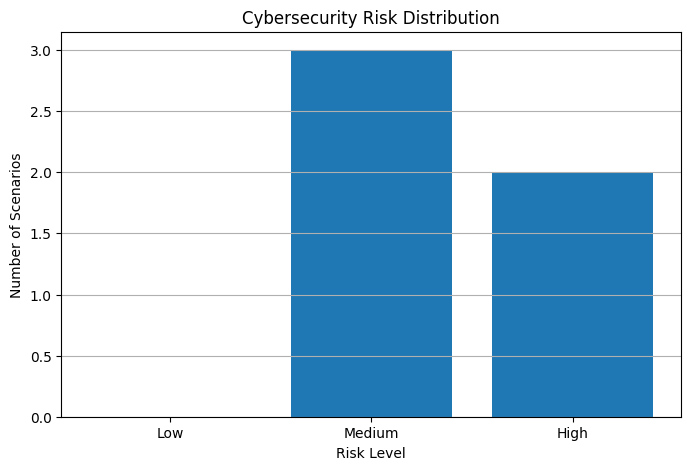

In [27]:
risk_counts = (
    final_results['risk']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'], fill_value=0)
)

plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.title("Cybersecurity Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Scenarios")
plt.grid(axis='y')

plt.show()

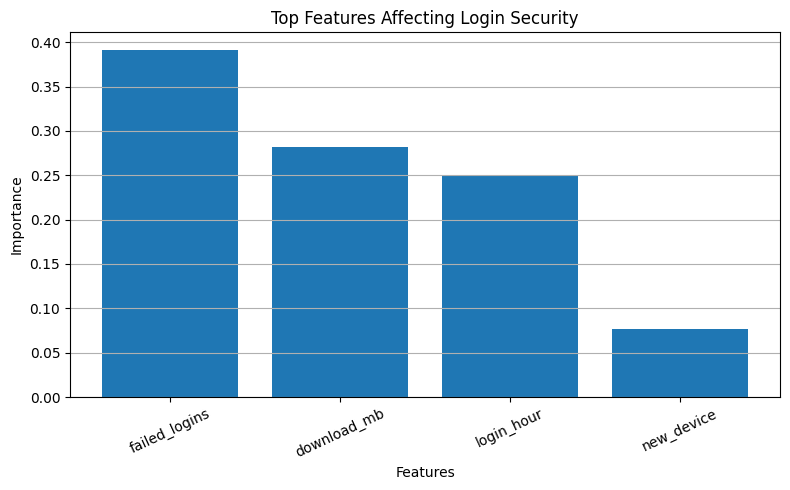

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.title("Top Features Affecting Login Security")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=25)
plt.grid(axis='y')
plt.tight_layout()

plt.show()

In [29]:
comparison = pd.DataFrame({

    'Module': [
        'Rule-Based AI',
        'Decision Tree',
        'Neural Network'
    ],

    'Result': [

        final_results['rule_category'].tolist(),

        final_results['tree_prediction'].tolist(),

        final_results['nn_prediction'].tolist()

    ]

})

print("THREE-MODULE PREDICTION COMPARISON")

display(comparison)

THREE-MODULE PREDICTION COMPARISON


,Module,Result
0,Rule-Based AI,"[Safe, Phishing, Safe, Safe, Safe]"
1,Decision Tree,"[Normal, Normal, Suspicious, Suspicious, Normal]"
2,Neural Network,"[Normal, Normal, Suspicious, Suspicious, Normal]"


In [30]:
# Save combined results
final_results.to_csv(
    'final_cybersecurity_results.csv',
    index=False
)

# Save feature importance
importance.to_csv(
    'feature_importance.csv',
    index=False
)

# Save comparison
comparison.to_csv(
    'model_comparison.csv',
    index=False
)

print("All output files saved successfully!")

# Download final results
files.download('final_cybersecurity_results.csv')
files.download('feature_importance.csv')
files.download('model_comparison.csv')

All output files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>